In [ ]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from IPython.core.display import display, HTML
display(HTML("<style>.container { width:85% !important; }</style>"))

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
from cosmoblender import tools as tls
from cosmoblender import qest
from cosmoblender import biases

# Directory to save to and load cached calculations from
outdir = './cached_calcs/'

/var/folders/zf/xwwhf0ps6yx93zy9ttqm3mm80000gn/T/ipykernel_62417/133338249.py:5: DeprecationWarning: Importing display from IPython.core.display is deprecated since IPython 7.14, please import from IPython.display
  from IPython.core.display import display, HTML


IMPORT ERROR: /opt/anaconda3/envs/for_cosmobl_v2/lib/python3.10/site-packages/quicklens-0.0.0-py3.10.egg/quicklens/mpi.py (No module named 'pypar'). Could not load pbs or pypar. MPI will not be used.
IMPORT ERROR: /opt/anaconda3/envs/for_cosmobl_v2/lib/python3.10/site-packages/quicklens-0.0.0-py3.10.egg/quicklens/shts/__init__.py (No module named 'fsht'). Try running 'python setup.py install' or 'python setup.py build_ext --inplace' from the quicklens directory.


# Calculate the biases to B-mode delensing

Take delensing of SO using single-frequency LAT lensing reconstructions (and E-modes) as an example

In [2]:
# You can specify a cosmological model -- in this case, match Websky
H0 = 68.
cosmoParams = {'As':2.08e-9,'ns':.965,'omch2':(0.31-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}

z_max = 5 #3
nZs = 40 #50
nMasses = 40  #30
Mmin = 1e10 #Keep this low -- the 2h term of the bispectrum bias can be sensitive to quite low-mass halos

# Set CIB halo model
cib_model='planck13'#'vierro'

# Initialise a halo model object for the calculation, using mostly default parameters
hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max)

In [3]:
SO_properties = {'nlev_t': np.array([6.3]),
                 'beam_size': np.array([1.4]),
                 'freq_GHz': np.array([143.]), 'nx_secbispec':128}

# Foreground cleaning? Only relevant if many frequencies are provided
MV_ILC_bool = False 
deproject_CIB = False
deproject_tSZ = False
fg_cleaning_dict = {'MV_ILC_bool':MV_ILC_bool, 'deproject_CIB':deproject_CIB, 'deproject_tSZ':deproject_tSZ}

# Initialise experiments with various different mass cuts
SO_5e15 = qest.experiment(lmax = 3500, massCut_Mvir=5e15, **SO_properties, 
                          **fg_cleaning_dict, fg=False, atm_fg=False)

In [ ]:
# We'll want to overlay a primordial B-mode spectrum with r=0.01 for comparison
# You can either compute it on the fly with Class, or load it from file if you've already computed and saved it
'''
from classy import Class
import numpy as np
import matplotlib.pyplot as plt
r=0.01
cosmo_w_r = Class()
params_w_r = {
    'output': 'tCl lCl pCl',
    'l_max_scalars': 5000,
    'l_max_tensors': 5000,
    'lensing': 'yes',
    'A_s': np.exp(3.0448)/1e10,
    'n_s': 0.96605, 
    'h': 0.6711,
    'omega_b': 0.02238,
    'omega_cdm': 0.12011,
    'modes': 's,t',
    'r': r}
cosmo_w_r.set(params_w_r)
cosmo_w_r.compute()

raw_cl_w_r = cosmo_w_r.raw_cl(lmax=5000)

ell_raw = np.arange(len(raw_cl_w_r['bb']))

clbb_tensor_r0p01_muKsq = 2.73**2*1e12*raw_cl_w_r['bb']
plt.loglog(ell_raw, clbb_tensor_r0p01_muKsq*ell_raw*(ell_raw+1)/(2*np.pi), color='blue')
plt.ylim([1e-6, 1e6])

# Save to file, with both the l and Cl values
np.savetxt('clbb_tensor_r0p01.txt', np.column_stack((ell_raw, clbb_tensor_r0p01_muKsq)), header='ell Clbb_tensor_r0p01')
'''

clbb_tensor_r0p01 = np.loadtxt('clbb_tensor_r0p01.txt')


In [5]:
get_cib=True
get_tsz=True
get_mixed=True
get_secondary_bispec_bias=True

### We can get separately get biases to the B-mode template auto- and cross-spectra

In [ ]:
ells, cl_Btemp_x_Blens_bias, cl_Btemp_x_Btemp_bias, cl_Bdel_x_Bdel_bias = hm_calc.get_bias_to_delensed_clbb(SO_5e15, get_cib=get_cib, get_tsz=get_tsz, get_mixed=get_mixed, get_secondary_bispec_bias=get_secondary_bispec_bias, bin_width_out_second_bispec_bias = 100)

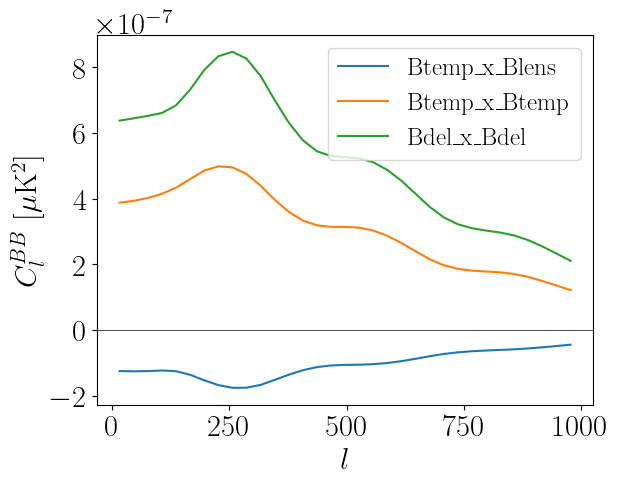

In [ ]:
plt.plot(ells, cl_Btemp_x_Blens_bias, label=r'Btemp_x_Blens')
plt.plot(ells, cl_Btemp_x_Btemp_bias, label=r'Btemp_x_Btemp')
plt.plot(ells, cl_Bdel_x_Bdel_bias, label=r'Bdel_x_Bdel')
plt.ylabel(r'$C_l^{BB}$ [$\mu$K$^2$]')
plt.xlabel(r'$l$')
plt.legend()
plt.axhline(0, color='k', lw=0.5)
#plt.ylim([-1e-6,6e-6])
#plt.ylim([-1e-7,2.1e-7])

### We can also check the impact of foreground cleaning

In [6]:
import os
SO_properties = {'nlev_t': np.array([52., 27., 5.8, 6.3, 15., 37.]),
                 'beam_size':np.array([7.4, 5.1, 2.2, 1.4, 1.0, 0.9]),
                 'freq_GHz': np.array([27.3, 41.7, 93., 143., 225.,278.])}

H0 = 68.
cosmoParams = {'As':2.08e-9,'ns':.965,'omch2':(0.31-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}

lmaxes = np.linspace(3000, 4500, 4).astype(int)

get_secondary_bispec_bias = True
parallelise_secondbispec = False

exp_list = []

for MV_ILC_bool, deproject_CIB, deproject_tSZ, label in zip([True, False, False], [False, True, False], [False, False, True], [r'MV ILC', r'CIB deproj. ILC', r'tSZ deproj. ILC']):
    fg_cleaning_dict = {'MV_ILC_bool':MV_ILC_bool, 'deproject_CIB':deproject_CIB, 'deproject_tSZ':deproject_tSZ}
    for lmax in lmaxes:
        print(lmax)
        filename = './dict_with_biases_auto_fgcleaning_{}_lmax{}'.format(label, lmax)
        if os.path.exists(filename+'.pkl'):
            experiment = qest.load_dict_of_biases(filename+'.pkl')
        else:
            experiment = qest.experiment(lmax = lmax, massCut_Mvir=2e14, **SO_properties, **fg_cleaning_dict)
        
            for which_bias in ['tsz', 'cib', 'mixed']:
                hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max)

                if which_bias=='total' or which_bias=='tsz':
                    hm_calc.get_tsz_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                                parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)
                if which_bias=='total' or which_bias=='cib':
                    hm_calc.get_cib_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                            parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)
                if which_bias=='total' or which_bias=='mixed':
                    hm_calc.get_mixed_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                                parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)
        
            experiment.save_biases(output_filename=filename)
            
        exp_list.append(experiment)

3000
3500
4000
4500
3000
3500
4000
4500
3000
3500
4000
4500


In [ ]:
# Split the lists into nine
exp_list_perpanel = [exp_list[:4], exp_list[4:8], exp_list[8:12], exp_list[12:16], exp_list[16:20], exp_list[20:24], exp_list[24:28], exp_list[28:32], exp_list[32:]]

In [ ]:
textwidth = 6.05 #inches
textheight = textwidth/2 #8.77 #inches

# Decide whether or not to break down the total into contributions from different halos
plot_breakdown = True

plotting_params = {'font.size':8, 'axes.labelsize':8, 'xtick.labelsize':8, 'ytick.labelsize':8, \
                      'font.family':'serif', 'text.usetex':True, 'figure.figsize': [textwidth, textheight],
                   'axes.titlesize':8, 'lines.linewidth':0.7}

plt.rcParams.update(plotting_params)
plots_dir = '/Users/antonbaleatolizancos/Projects/lensing_rec_biases/paper/5f71fb65ea173d000120afc7/'

# Hacky way of typsetting scientific notation
def as_si(x, ndp):
    '''
    From https://stackoverflow.com/questions/31453422/displaying-numbers-with-x-instead-of-e-scientific-notation-in-matplotlib/31453961
    - Inputs:
        * x = number
        * ndp = number of decimal places
    '''
    s = '{x:0.{ndp:d}e}'.format(x=x, ndp=ndp)
    m, e = s.split('e')
    return r'{m:s}\times 10^{{{e:d}}}'.format(m=m, e=int(e))

In [9]:
import quicklens as ql
pix = ql.maps.cfft(1024, 1/60./180.*np.pi)

(-9e-09, 2.2e-08)

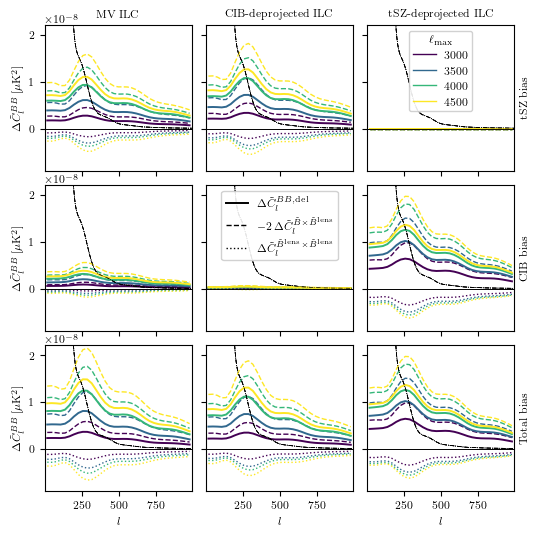

In [ ]:
lbins = np.arange(2, 1000, 30)

import matplotlib.cm as cm
colors = cm.viridis(np.linspace(0, 1, len(lmaxes)))

fig, axes = plt.subplots(3, 3, sharex=True, sharey=True, figsize=(textwidth, 2*textheight), squeeze=True)  

[ax.set_xlabel(r'$l$') for ax in axes[2, :]]
[ax.set_ylabel(r'$\Delta \tilde{C}_{l}^{BB} \,[\mu\mathrm{K}^2]$') for ax in axes[:,0]]
[ax.set_title(lab) for ax, lab in zip(axes[0, :], [r'MV ILC', r'CIB-deprojected ILC', r'tSZ-deprojected ILC'])]

# Replace the colorbar with a legend to go in the third subplot
[axes[0,2].plot([],[], color=colors[i], lw=1, label=lmaxes.astype(int).astype(str)[i]) for i in range(len(lmaxes))]
axes[0,2].legend(title=r'$\ell_{\rm max}$', fontsize=8, title_fontsize=8, loc='upper center', ncols=1, framealpha=0.9)

# Add a second legend to the same subplot
axes[1,1].plot([],[], color='k', ls='-', lw=1.4, label=r'$\Delta \tilde{C}_{l}^{BB, \mathrm{del}}$')
axes[1,1].plot([],[], color='k', ls='--', lw=1, label=r'$-2\,\Delta \tilde{C}_{l}^{\tilde{B}\times \tilde{B}^{\mathrm{lens}}}$')
axes[1,1].plot([],[], color='k', ls=':', lw=1, label=r'$\Delta \tilde{C}_{l}^{\tilde{B}^{\mathrm{lens}} \times \tilde{B}^{\mathrm{lens}}}$')
axes[1,1].legend(fontsize=8, loc='upper center', framealpha=0.9)


plot_breakdown = False

for exp_list_, fgcl_label, col in zip(exp_list_perpanel, 3*[r'MV ILC', r'CIB deproj. ILC', r'tSZ deproj. ILC'], 3*[0,1,2]): 
    for row, foreground in zip([0,1,2], ['tsz', 'cib', 'total']):
        axes[row,col].axhline(0, color='k', lw=0.5, ls='-')   
        for color, experiment, lmax in zip(colors, exp_list_, lmaxes):
            basic_exp = qest.experiment(lmax = lmax, massCut_Mvir=2e14, **SO_properties, **fg_cleaning_dict)
            ells_for_clkk = np.arange(lmax + 1, dtype=float)
            clkk_bias_tot = np.zeros_like(ells_for_clkk, dtype=complex)
            clkcross_bias_tot = np.zeros_like(ells_for_clkk, dtype=complex)
        
            for coupling in ['prim_bispec', 'second_bispec', 'trispec']:
                for linestyle, term in zip([':', '-.', '-'], ['1h', '2h']):
                    if coupling=='second_bispec':
                        try:
                            clkk_bias_tot += np.interp(ells_for_clkk, experiment.biases['second_bispec_bias_ells'], experiment.biases[foreground][coupling][term])
                        except:
                            clkk_bias_tot += np.interp(ells_for_clkk, experiment['second_bispec_bias_ells'], experiment[foreground][coupling][term])
                    else:
                        try:
                            clkk_bias_tot += np.nan_to_num(np.interp(ells_for_clkk, experiment.biases['ells'], experiment.biases[foreground][coupling][term]))
                        except:
                            clkk_bias_tot += np.nan_to_num(np.interp(ells_for_clkk, experiment['ells'], experiment[foreground][coupling][term]))
                        if coupling=='prim_bispec':
                            # The prim bispec bias to the recXtrueKappa is half of the prim bispec bias to the auto
                            try:
                                clkcross_bias_tot += np.nan_to_num(0.5 * np.interp(ells_for_clkk, experiment.biases['ells'], experiment.biases[foreground][coupling][term]))
                            except:
                                clkcross_bias_tot += np.nan_to_num(0.5 * np.interp(ells_for_clkk, experiment['ells'], experiment[foreground][coupling][term]))
            
            cl_Btemp_x_Blens_bias_bcl = tls.calculate_cl_bias(basic_exp.pix,
                                                                basic_exp.W_E(lmax) * basic_exp.sky.cmb[0, 0].funlensedEE(
                                                                    ells_for_clkk),
                                                                basic_exp.W_phi(lmax) * clkcross_bias_tot, lbins)
            cl_Btemp_x_Btemp_bias_bcl = tls.calculate_cl_bias(basic_exp.pix, basic_exp.W_E(lmax) ** 2 * basic_exp.clee_tot,
                                                                basic_exp.W_phi(lmax) ** 2 * clkk_bias_tot, lbins)
            cl_Bdel_x_Bdel_bias_array = - 2 * cl_Btemp_x_Blens_bias_bcl.specs['cl'] + cl_Btemp_x_Btemp_bias_bcl.specs['cl']

            cl_Btemp_x_Blens_bias_bcl.ls, cl_Btemp_x_Blens_bias_bcl.specs['cl'],\
                    cl_Btemp_x_Btemp_bias_bcl.specs['cl'], cl_Bdel_x_Bdel_bias_array
            
            signal = np.interp(cl_Btemp_x_Blens_bias_bcl.ls, basic_exp.cl_len.ls, basic_exp.cl_len.clbb)
            axes[row,col].plot(cl_Btemp_x_Blens_bias_bcl.ls, -2*cl_Btemp_x_Blens_bias_bcl.specs['cl'], color=color, ls='--', label=None, lw=1.)
            axes[row,col].plot(cl_Btemp_x_Blens_bias_bcl.ls, cl_Btemp_x_Btemp_bias_bcl.specs['cl'], color=color, ls=':', label=None, lw=1.)         
            axes[row,col].plot(cl_Btemp_x_Blens_bias_bcl.ls, cl_Bdel_x_Bdel_bias_array, color=color, ls='-', label=None, lw=1.4)
            axes[row,col].plot(clbb_tensor_r0p01[:,0], clbb_tensor_r0p01[:,1], color='k', lw=0.5, ls='-.')         

    ax = plt.gca()
    #ax.set_yscale('symlog', linthresh=1e-3)

# Set y label on right
[ax.yaxis.set_label_position("right") for ax in axes[:, 2]]
[ax.set_ylabel(lab) for ax, lab in zip(axes[:, 2], [r'tSZ bias', r'CIB bias', r'Total bias'])]

# Remove the horizontal space between the plots
plt.subplots_adjust(hspace=0.1, wspace=0.1)

plt.xlim([2, 990])
plt.ylim([-0.9e-8, 2.2e-8])

#plt.ylim([-1e-1,-1e-3])#plt.ylim([-1.2,1.2])

plt.savefig(plots_dir+'delensing_biases_vs_fgcleaning_and_lmax.pdf', bbox_inches='tight', dpi=1000)

### We can explore the impact of halo mass cuts

In [ ]:
Mcuts = [1e14, 2e14, 5e14, 1e15, 5e15]
lmax = 3000

# Foreground cleaning? Only relevant if many frequencies are provided
MV_ILC_bool = True 
deproject_CIB = False
deproject_tSZ = False
fg_cleaning_dict = {'MV_ILC_bool':MV_ILC_bool, 'deproject_CIB':deproject_CIB, 'deproject_tSZ':deproject_tSZ}


which_bias='total'
get_secondary_bispec_bias = True
parallelise_secondbispec = False

exp_list = []
for Mcut in Mcuts:
    print('Working on mass cut: ', np.log10(Mcut))
    filename = outdir+'dict_with_biases_auto_varyingmasses_lmax{}_Mcut{}e14'.format(int(lmax), int(Mcut/1e14))
    if os.path.exists(filename+'.pkl'):
        experiment = qest.load_dict_of_biases(filename+'.pkl')
    else:
        experiment = qest.experiment(lmax = lmax, massCut_Mvir=Mcut, **SO_properties, **fg_cleaning_dict)
        hm_calc = biases.hm_framework(cosmoParams=cosmoParams, m_min=Mmin, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max)


        if which_bias=='total' or which_bias=='tsz':
            hm_calc.get_tsz_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                        parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)
        if which_bias=='total' or which_bias=='cib':
            hm_calc.get_cib_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                    parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)
        if which_bias=='total' or which_bias=='mixed':
            hm_calc.get_mixed_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                        parallelise_secondbispec=parallelise_secondbispec, bin_width_out_second_bispec_bias=100)
    
        experiment.save_biases(output_filename=filename)
    
    exp_list.append(experiment)

Working on mass cut:  14.0
Working on mass cut:  14.301029995663981
Working on mass cut:  14.698970004336019
Working on mass cut:  15.0
Working on mass cut:  15.698970004336019


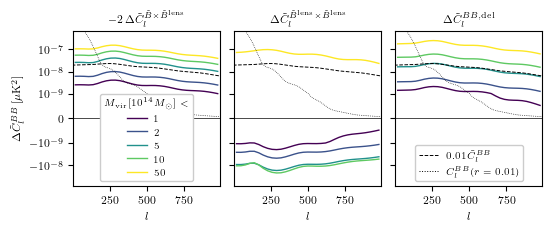

In [ ]:
lbins = np.arange(2, 1000, 30)

import matplotlib.cm as cm
colors = cm.viridis(np.linspace(0, 1, len(Mcuts)))

fig, axes = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(textwidth, textwidth/3), squeeze=True)  

[ax.set_xlabel(r'$l$') for ax in axes]
axes[0].set_ylabel(r'$\Delta \tilde{C}_{l}^{BB} \,[\mu\mathrm{K}^2]$')
[ax.axhline(0, color='k', lw=0.5, ls='-')  for ax in axes]

spec_names = [r'$-2\,\Delta \tilde{C}_{l}^{\tilde{B}\times \tilde{B}^{\mathrm{lens}}}$',r'$\Delta \tilde{C}_{l}^{\tilde{B}^{\mathrm{lens}} \times \tilde{B}^{\mathrm{lens}}}$', r'$\Delta \tilde{C}_{l}^{BB, \mathrm{del}}$']
[ax.set_title(lab) for ax, lab in zip(axes, spec_names)]

plot_breakdown = False

for color, experiment, Mcut in zip(colors, exp_list, Mcuts):
    basic_exp = qest.experiment(lmax = lmax, massCut_Mvir=Mcut, **SO_properties, **fg_cleaning_dict)
    ells_for_clkk = np.arange(lmax + 1, dtype=float)
    clkk_bias_tot = np.zeros_like(ells_for_clkk, dtype=complex)
    clkcross_bias_tot = np.zeros_like(ells_for_clkk, dtype=complex)
    for foreground in ['total']:
        for coupling in ['prim_bispec', 'second_bispec', 'trispec']:
            for linestyle, term in zip([':', '-.', '-'], ['1h', '2h']):
                if coupling=='second_bispec':
                    try:
                        clkk_bias_tot += np.interp(ells_for_clkk, experiment.biases['second_bispec_bias_ells'], experiment.biases[foreground][coupling][term])
                    except:
                        clkk_bias_tot += np.interp(ells_for_clkk, experiment['second_bispec_bias_ells'], experiment[foreground][coupling][term])
                else:
                    try:
                        clkk_bias_tot += np.nan_to_num(np.interp(ells_for_clkk, experiment.biases['ells'], experiment.biases[foreground][coupling][term]))
                    except:
                        clkk_bias_tot += np.nan_to_num(np.interp(ells_for_clkk, experiment['ells'], experiment[foreground][coupling][term]))
                    if coupling=='prim_bispec':
                        # The prim bispec bias to the recXtrueKappa is half of the prim bispec bias to the auto
                        try:
                            clkcross_bias_tot += np.nan_to_num(0.5 * np.interp(ells_for_clkk, experiment.biases['ells'], experiment.biases[foreground][coupling][term]))
                        except:
                            clkcross_bias_tot += np.nan_to_num(0.5 * np.interp(ells_for_clkk, experiment['ells'], experiment[foreground][coupling][term]))
        
        cl_Btemp_x_Blens_bias_bcl = tls.calculate_cl_bias(basic_exp.pix,
                                                            basic_exp.W_E(lmax) * basic_exp.sky.cmb[0, 0].funlensedEE(
                                                                ells_for_clkk),
                                                            basic_exp.W_phi(lmax) * clkcross_bias_tot, lbins)
        cl_Btemp_x_Btemp_bias_bcl = tls.calculate_cl_bias(basic_exp.pix, basic_exp.W_E(lmax) ** 2 * basic_exp.clee_tot,
                                                            basic_exp.W_phi(lmax) ** 2 * clkk_bias_tot, lbins)
        cl_Bdel_x_Bdel_bias_array = - 2 * cl_Btemp_x_Blens_bias_bcl.specs['cl'] + cl_Btemp_x_Btemp_bias_bcl.specs['cl']

        cl_Btemp_x_Blens_bias_bcl.ls, cl_Btemp_x_Blens_bias_bcl.specs['cl'],\
                cl_Btemp_x_Btemp_bias_bcl.specs['cl'], cl_Bdel_x_Bdel_bias_array
        
        axes[0].plot(cl_Btemp_x_Blens_bias_bcl.ls, -2*cl_Btemp_x_Blens_bias_bcl.specs['cl'], color=color, ls='-', label=None, lw=1.)
        axes[1].plot(cl_Btemp_x_Blens_bias_bcl.ls, cl_Btemp_x_Btemp_bias_bcl.specs['cl'], color=color, ls='-', label=None, lw=1.)         
        axes[2].plot(cl_Btemp_x_Blens_bias_bcl.ls, cl_Bdel_x_Bdel_bias_array, color=color, ls='-', label=None, lw=1.)    

[ax.plot(0.01*SO_5e15.cl_len.clbb, ls='--', color='k') for ax in axes]

axes[0].set_yscale('symlog', linthresh=1e-9)        

# Replace the colorbar with a legend to go in the third subplot
[axes[0].plot([],[], color=colors[i], lw=1, label=(np.array(Mcuts)/1e14).astype(int)[i]) for i in range(len(Mcuts))]
axes[0].legend(title=r'$M_{\rm vir}$\,[$10^{14}\,M_{\odot}$] $<$ ', fontsize=7, title_fontsize=7, loc='lower center', ncols=1, framealpha=1)

# Add an ad hoc legend to axes[2]
axes[2].plot([],[], color='k', ls='--', label=r'0.01\,$\tilde{C}_{l}^{BB}$')

# Add a primordical component to all axes
[axes[i].plot(clbb_tensor_r0p01[:,0], clbb_tensor_r0p01[:,1], color='k', lw=0.5, ls=':') for i in range(3)]
axes[2].plot([],[], color='k', ls=':', label=r'$C_{l}^{BB}(r=0.01)$')
axes[2].legend(fontsize=7,loc='lower center', ncols=1, framealpha=1)

# Remove the horizontal space between the plots
plt.subplots_adjust(hspace=0.1, wspace=0.1)

plt.xlim([2, 990])
plt.ylim([-0.9e-7,0.7e-6])

plt.savefig(plots_dir+'delensing_biases_vs_Masscut.pdf', bbox_inches='tight', dpi=1000)

In [15]:
lbins = np.arange(2, 1000, 30)

cl_Bdel_x_Bdel_bias_array_list = []
# First, calcualate the total delensing bias
for color, experiment, Mcut in zip(colors, exp_list, Mcuts):
    basic_exp = qest.experiment(lmax = lmax, massCut_Mvir=Mcut, **SO_properties, **fg_cleaning_dict)
    ells_for_clkk = np.arange(lmax + 1, dtype=float)
    clkk_bias_tot = np.zeros_like(ells_for_clkk, dtype=complex)
    clkcross_bias_tot = np.zeros_like(ells_for_clkk, dtype=complex)
    for foreground in ['total']:
        for coupling in ['prim_bispec', 'second_bispec', 'trispec']:
            for linestyle, term in zip([':', '-.', '-'], ['1h', '2h']):
                if coupling=='second_bispec':
                    try:
                        clkk_bias_tot += np.interp(ells_for_clkk, experiment.biases['second_bispec_bias_ells'], experiment.biases[foreground][coupling][term])
                    except:
                        clkk_bias_tot += np.interp(ells_for_clkk, experiment['second_bispec_bias_ells'], experiment[foreground][coupling][term])
                else:
                    try:
                        clkk_bias_tot += np.nan_to_num(np.interp(ells_for_clkk, experiment.biases['ells'], experiment.biases[foreground][coupling][term]))
                    except:
                        clkk_bias_tot += np.nan_to_num(np.interp(ells_for_clkk, experiment['ells'], experiment[foreground][coupling][term]))
                    if coupling=='prim_bispec':
                        # The prim bispec bias to the recXtrueKappa is half of the prim bispec bias to the auto
                        try:
                            clkcross_bias_tot += np.nan_to_num(0.5 * np.interp(ells_for_clkk, experiment.biases['ells'], experiment.biases[foreground][coupling][term]))
                        except:
                            clkcross_bias_tot += np.nan_to_num(0.5 * np.interp(ells_for_clkk, experiment['ells'], experiment[foreground][coupling][term]))
        
    cl_Btemp_x_Blens_bias_bcl = tls.calculate_cl_bias(basic_exp.pix,
                                                            basic_exp.W_E(lmax) * basic_exp.sky.cmb[0, 0].funlensedEE(
                                                                ells_for_clkk),
                                                            basic_exp.W_phi(lmax) * clkcross_bias_tot, lbins)
    cl_Btemp_x_Btemp_bias_bcl = tls.calculate_cl_bias(basic_exp.pix, basic_exp.W_E(lmax) ** 2 * basic_exp.clee_tot,
                                                            basic_exp.W_phi(lmax) ** 2 * clkk_bias_tot, lbins)
    cl_Bdel_x_Bdel_bias_array_list.append(- 2 * cl_Btemp_x_Blens_bias_bcl.specs['cl'] + cl_Btemp_x_Btemp_bias_bcl.specs['cl'])


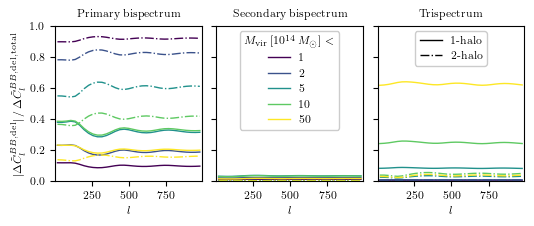

In [ ]:
import matplotlib.cm as cm
colors = cm.viridis(np.linspace(0, 1, len(Mcuts)))

fig, axes = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(textwidth, textwidth/3), squeeze=True)  

[ax.set_xlabel(r'$l$') for ax in axes]
#axes[0].set_ylabel(r'$\frac{|\Delta \tilde{C}_{l}^{BB, \mathrm{del}}|}{\Delta \tilde{C}_{l}^{BB, \mathrm{del, total}} }$')
axes[0].set_ylabel(r'$|\Delta \tilde{C}_{l}^{BB, \mathrm{del}}| \, / \, \Delta \tilde{C}_{l}^{BB, \mathrm{del, total}} $')
[ax.axhline(0, color='k', lw=0.5, ls='-')  for ax in axes]

spec_names = [r'Primary bispectrum',r'Secondary bispectrum', r'Trispectrum']
[ax.set_title(lab) for ax, lab in zip(axes, spec_names)]

for color, experiment, Mcut, total_clbbdel in zip(colors, exp_list, Mcuts, cl_Bdel_x_Bdel_bias_array_list):
    basic_exp = qest.experiment(lmax = lmax, massCut_Mvir=Mcut, **SO_properties, **fg_cleaning_dict)
    ells_for_clkk = np.arange(lmax + 1, dtype=float)
    for foreground in ['total']:
        for row, coupling in zip([0,1,2], ['prim_bispec', 'second_bispec', 'trispec']):
            for linestyle, term in zip(['-', '-.', '-'], ['1h', '2h']):
                clkk_bias_tot = np.zeros_like(ells_for_clkk, dtype=complex)
                clkcross_bias_tot = np.zeros_like(ells_for_clkk, dtype=complex)
                if coupling=='second_bispec':
                    try:
                        clkk_bias_tot += np.interp(ells_for_clkk, experiment.biases['second_bispec_bias_ells'], experiment.biases[foreground][coupling][term])
                    except:
                        clkk_bias_tot += np.interp(ells_for_clkk, experiment['second_bispec_bias_ells'], experiment[foreground][coupling][term])
                else:
                    try:
                        clkk_bias_tot += np.nan_to_num(np.interp(ells_for_clkk, experiment.biases['ells'], experiment.biases[foreground][coupling][term]))
                    except:
                        clkk_bias_tot += np.nan_to_num(np.interp(ells_for_clkk, experiment['ells'], experiment[foreground][coupling][term]))
                    if coupling=='prim_bispec':
                        # The prim bispec bias to the recXtrueKappa is half of the prim bispec bias to the auto
                        try:
                            clkcross_bias_tot += np.nan_to_num(0.5 * np.interp(ells_for_clkk, experiment.biases['ells'], experiment.biases[foreground][coupling][term]))
                        except:
                            clkcross_bias_tot += np.nan_to_num(0.5 * np.interp(ells_for_clkk, experiment['ells'], experiment[foreground][coupling][term]))
        
                cl_Btemp_x_Blens_bias_bcl = tls.calculate_cl_bias(basic_exp.pix,
                                                                basic_exp.W_E(lmax) * basic_exp.sky.cmb[0, 0].funlensedEE(
                                                                    ells_for_clkk),
                                                                basic_exp.W_phi(lmax) * clkcross_bias_tot, lbins)
                cl_Btemp_x_Btemp_bias_bcl = tls.calculate_cl_bias(basic_exp.pix, basic_exp.W_E(lmax) ** 2 * basic_exp.clee_tot,
                                                                basic_exp.W_phi(lmax) ** 2 * clkk_bias_tot, lbins)
                tot_this_term = - 2 * cl_Btemp_x_Blens_bias_bcl.specs['cl'] + cl_Btemp_x_Btemp_bias_bcl.specs['cl']
            
                axes[row].plot(cl_Btemp_x_Blens_bias_bcl.ls, np.abs(tot_this_term/total_clbbdel), color=color, ls=linestyle, label=None, lw=1.)         

#axes[0].set_yscale('symlog', linthresh=1e-2)     
axes[0].set_yscale('linear')  
axes[0].set_ylim([0,1])      

# Replace the colorbar with a legend to go in the third subplot
[axes[1].plot([],[], color=colors[i], lw=1, label=(np.array(Mcuts)/1e14).astype(int)[i]) for i in range(len(Mcuts))]
axes[1].legend(title=r'$M_{\rm vir}$\,[$10^{14}\,M_{\odot}$] $<$ ', fontsize=8, title_fontsize=8, loc='upper center', ncols=1, framealpha=1)

axes[2].plot([],[], color='k', lw=1, ls='-', label=r'1-halo')
axes[2].plot([],[], color='k', lw=1, ls='-.', label=r'2-halo')
axes[2].legend(loc='upper center', framealpha=1, fontsize=8, title_fontsize=8, ncol=1)


# Remove the horizontal space between the plots
plt.subplots_adjust(hspace=0.05, wspace=0.1)

plt.xlim([2, 990])
#plt.ylim([-1e-1,-1e-3])#plt.ylim([-1.2,1.2])

plt.savefig(plots_dir+'delensing_biases_structure_vs_Masscut.pdf', bbox_inches='tight', dpi=1000)